Давайте подивимося, як LSTM можна використовувати для побудови нейронної мережі прогнозування часових.

Будемо працювати з задачею прогнозування кількості пасажирів міжнародних авіаліній. З цим набором даних ми вже працювали в лекції "Time Series Analysis" і ви зможете порівняти результати :)

Задача полягає в тому, щоб за заданими роком і місяцем передбачити кількість пасажирів міжнародних авіаліній в одиницях виміру 1,000. Дані охоплюють період з січня 1949 року по грудень 1960 року, тобто 12 років, зі 144 спостереженнями.

Це регресійна задача. Тобто, знаючи кількість пасажирів (в тисячах) за останні місяці, можна передбачити, якою буде кількість пасажирів у наступному місяці. Набір даних має лише одну характеристику: "Кількість пасажирів" - `Passengers`.

Далі вже наведений код для читання даних, але нам їх ще треба буде трошки обробити.

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

# Завантаження даних
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)
df.set_index('Month', inplace=True)
display(df.head())

,Passengers
Month,
1949-01,112
1949-02,118
1949-03,132
1949-04,129
1949-05,121


**Завдання 1.** Створіть змінну типу `numpy.ndarray`, яка містить значення кількості пасажирів в форматі `float32`. Такий формат даних нам треба для тренування нейромережі.

In [4]:
data = df['Passengers'].to_numpy(dtype=np.float32)
data[:5]

array([112., 118., 132., 129., 121.], dtype=float32)

Очікуваний результат:
```array([112., 118., 132., 129., 121.], dtype=float32)```

**Завдання 2**. Розбийте дані на тренувальні і валідаційні у співвідношенні 67% йде у тренування, 33 - у валідацію. Памʼятаємо, що ми працюємо з tim series, відповідно, навчаємось на давніших, валідуємось - на новіших.

In [5]:
train_size = int(len(data) * 0.67)

train_data = data[:train_size]
val_data = data[train_size:]

print("Train:", len(train_data))
print("Validation:", len(val_data))

Train: 96
Validation: 48


**Завдання 3**.

Реалізуйте функцію `create_dataset`, яка перетворить одномірний часовий ряд (набір даних) у формат, придатний для тренування нейромережі.

Функція повинна приймати два аргументи:
- `dataset` — numpy-масив часового ряду,
- `lookback` — кількість попередніх кроків, які використовуватимуться для передбачення.

Функція повинна повернути два **тензори** PyTorch:
- `X` — набір ознак (вікно попередніх значень),
- `y` — цільові значення (наступні після вікна кроки).

Дані ми будемо подавати моделі в наступному форматі:
`
tensor([[112.],
        [118.],
        [132.],
        [129.],
        [121.]])
`
Відповідно першою розмірністю буде йти розмір вхідного батча, а другою - розмір вхіднизх даних і в нас це 1, бо лише одне значення на вході щоразу.

Після виконання завдання запустіть код нижче. Ми будемо передбачати на основі кількості пасажирів в попередній день кількість пасажирів в наступний, тому `lookback == 1`.

In [ ]:
%pip install torch

In [8]:
import torch

def create_dataset(dataset, lookback):
    X, y = [], []

    for i in range(len(dataset) - lookback):
        X.append(dataset[i:i + lookback])
        y.append(dataset[i + lookback])

    X = torch.tensor(np.array(X), dtype=torch.float32)
    y = torch.tensor(np.array(y), dtype=torch.float32).reshape(-1, 1)

    return X, y

In [9]:
train = train_data
test = val_data

In [10]:
lookback = 1
X_train, y_train = create_dataset(train, lookback=lookback)
X_test, y_test = create_dataset(test, lookback=lookback)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

torch.Size([95, 1]) torch.Size([95, 1])
torch.Size([47, 1]) torch.Size([47, 1])


Очікуваний результат:
```
torch.Size([95, 1]) torch.Size([95, 1])
torch.Size([47, 1]) torch.Size([47, 1])
```

**Завдання 4**.

Зверніть увагу на розмірності в попередньому завданні. Ми
З допомогою модуля `torch.nn` опишіть клас `AirModel`, який є нейронною мережею для прогнозування кількості пасажирів за допомогою LSTM.

1. **Конструктор класу** повинен приймати параметри `hidden_size`, `num_layers` та ініціювати шари:
   - LSTM-шар з наступними параметрами:
     - `input_size` — кожна точка часового ряду є окремим входом,,
     - `hidden_size` — заданий в конструкторі класу мережі,
     - `num_layers=1` — кількість шарів LSTM, задана в конструкторі мережі,
     - `batch_first=True` — визначає, що першим виміром є розмір батчу.
   - Лінійний шар (`nn.Linear`) для перетворення виходу LSTM на прогноз однієї точки.

2. **Метод forward** повинен виконувати наступні дії:
   - Передати вхідний тензор через LSTM-шар і отримати виходи (ігноруючи приховані стани).
   - Пропустити вихід LSTM через лінійний шар для отримання остаточного прогнозу.

Створіть об'єкт класу `AirModel` зі значеннями параметрів `hidden_size=50`, `num_layers=1` і протестуйте роботу моделі на вхідному тензорі `tensor([[112.]])`. На цьому етапі ми маємо переконатись, що модель здатна генерувати передбачення з рандомно ініційованими вагами.

In [11]:
import torch.nn as nn

class AirModel(nn.Module):
    def __init__(self, hidden_size, num_layers):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )
        self.linear = nn.Linear(hidden_size, 1)

    def forward(self, x):
        x = x.unsqueeze(-1)
        x, _ = self.lstm(x)
        x = self.linear(x)
        return x.squeeze(-1)

model = AirModel(hidden_size=50, num_layers=1)

test_input = torch.tensor([[112.]])

model.eval()
with torch.no_grad():
    prediction = model(test_input)

print(prediction)

tensor([[-0.1255]])


**Завдання 5**.

Створіть об'єкт DataLoader для завантаження даних, використовуючи тренувальні вибірки `X_train` та `y_train`. Ваш DataLoader повинен виконувати наступні вимоги:

1. Використовувати клас `TensorDataset`, щоб об'єднати тензори ознак `X_train` і цільових значень `y_train`.
2. Дані повинні завантажуватися невеликими батчами розміром 8 за допомогою параметра `batch_size`.
3. Використовувати параметр `shuffle=True`, щоб дані перемішувалися перед кожною епохою тренування.


In [12]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

**Завдання 6**.

1. Реалізуйте навчання нейронної мережі `AirModel` для прогнозування часових рядів, використовуючи Adam-оптимізатор та функцію втрат MSE (середньоквадратичну похибку).
2. Створіть цикл тренування для 2000 епох, у якому на кожній епосі:
   - Виконуйте крок тренування моделі (прямий прохід, обчислення похибки, зворотний прохід і оновлення ваг).
   - Підраховуйте середню похибку на кожному батчі даних і зберігайте її у списку `losses`.
3. Раз на 100 епох проводьте валідацію моделі:
   - Перевіряйте модель на тренувальних та тестових даних без оновлення ваг.
   - Обчислюйте корінь середньоквадратичної похибки (RMSE) для тренувальної та тестової вибірок і виводьте результати на екран.
   
**Примітка:**
- Використовуйте вже створений `DataLoader` для отримання батчів даних.
- Валідацію виконуйте в режимі `eval()`, вимикаючи обчислення градієнтів з `torch.no_grad()`.

**Приклад виходу:**
```
Epoch 0: train RMSE 12.3456, test RMSE 15.6789
Epoch 100: train RMSE 9.8765, test RMSE 12.3456
...
```

In [13]:
import numpy as np

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

losses = []

for epoch in range(2000):
    model.train()
    batch_losses = []

    for X_batch, y_batch in train_loader:
        y_pred = model(X_batch)

        loss = loss_fn(y_pred, y_batch)

        optimizer.zero_grad()
        loss.backward()

        optimizer.step()

        batch_losses.append(loss.item())

    losses.append(np.mean(batch_losses))

    if epoch % 100 == 0:
        model.eval()

        with torch.no_grad():
            train_pred = model(X_train)
            test_pred = model(X_test)

            train_rmse = torch.sqrt(loss_fn(train_pred, y_train))
            test_rmse = torch.sqrt(loss_fn(test_pred, y_test))

        print(f"Epoch {epoch}: train RMSE {train_rmse.item():.4f}, test RMSE {test_rmse.item():.4f}")

Epoch 0: train RMSE 226.1623, test RMSE 422.5734
Epoch 100: train RMSE 187.1239, test RMSE 381.7400
Epoch 200: train RMSE 155.4378, test RMSE 347.6602
Epoch 300: train RMSE 127.8756, test RMSE 316.5925
Epoch 400: train RMSE 104.7245, test RMSE 288.1582
Epoch 500: train RMSE 86.4574, test RMSE 262.5512
Epoch 600: train RMSE 69.9397, test RMSE 237.9106
Epoch 700: train RMSE 56.8151, test RMSE 214.9800
Epoch 800: train RMSE 46.4486, test RMSE 194.1698
Epoch 900: train RMSE 39.0551, test RMSE 175.5082
Epoch 1000: train RMSE 34.5350, test RMSE 159.8765
Epoch 1100: train RMSE 31.3322, test RMSE 145.6283
Epoch 1200: train RMSE 27.5491, test RMSE 134.9880
Epoch 1300: train RMSE 26.1032, test RMSE 126.5441
Epoch 1400: train RMSE 26.6932, test RMSE 119.1318
Epoch 1500: train RMSE 25.7487, test RMSE 115.2228
Epoch 1600: train RMSE 25.2070, test RMSE 110.6143
Epoch 1700: train RMSE 23.7999, test RMSE 106.4578
Epoch 1800: train RMSE 24.1531, test RMSE 104.5715
Epoch 1900: train RMSE 23.6370, test R

Модель LSTM успішно навчалася протягом 2000 епох. Похибка RMSE поступово зменшувалася на тренувальних і тестових даних. Однак на тестовій вибірці похибка залишається значно вищою, що свідчить про недостатню точність прогнозування нових значень.

**Завдання 7.** Побудуйте графік лосів. Зробіть висновок з графіку, чи навчилась модель?

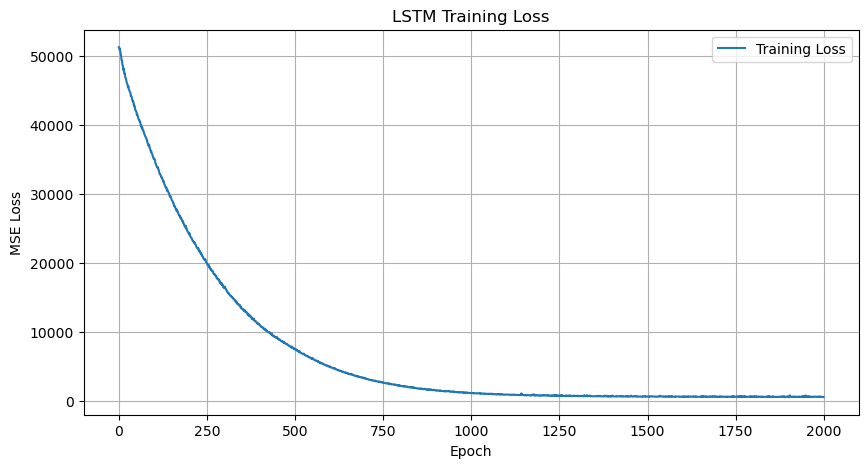

In [14]:
plt.figure(figsize=(10, 5))
plt.plot(losses, label='Training Loss')

plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('LSTM Training Loss')
plt.legend()
plt.grid(True)
plt.show()

Модель LSTM навчилася, оскільки значення функції втрат (Loss) поступово зменшувалося та стабілізувалося. Це означає, що модель знаходить закономірності в тренувальних даних. Проте похибка на тестових даних залишається високою, тому модель ще можна покращити.

Модель навчилась, але не факт, що точно)

Доволі неочікувано, що середньоквадратичне відхилення тестового набору даних буде на порядок більшим за одиниці в нашому наборі даних. Середньоквадратичне відхилення 100 означає, що прогноз і фактичне значення будуть відрізнятися в середньому на 100 (тобто, 100 000 пасажирів у цьому наборі даних).



Щоб краще зрозуміти якість прогнозу, ви можете побудувати графік з кодом нижче (а ще нижче - описано, що відбувається в цьому коді, бо це теж корисно зрозуміти):

In [16]:
timeseries = data

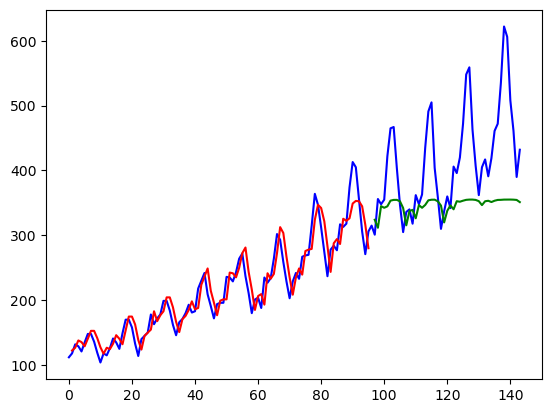

In [17]:
def plot_predicts():
  with torch.no_grad():
      # Зсув прогнозів для тренувальних даних
      train_plot = np.ones_like(timeseries) * np.nan
      y_pred = model(X_train)
      y_pred = y_pred[:, -1]
      train_plot[lookback:train_size] = model(X_train)[:, -1]

      # Зсув прогнозів для тестових даних
      test_plot = np.ones_like(timeseries) * np.nan
      test_plot[train_size+lookback:len(timeseries)] = model(X_test)[:, -1]

  # Візуалізація результатів
  plt.plot(timeseries, c='b')  # Реальні дані
  plt.plot(train_plot, c='r')  # Прогнози на тренувальних даних
  plt.plot(test_plot, c='g')   # Прогнози на тестових даних
  plt.show()

plot_predicts()

Модель LSTM добре прогнозує тренувальні дані, але на тестових показує значно гірші результати. Вона не враховує зростання кількості пасажирів і сезонні коливання. Отже, модель навчилася, але її точність на нових даних потребує покращення.

**Що відбувається в коді вище.** В цьому коді здійснюється процес прогнозування часових рядів за допомогою LSTM моделі, а також виведення графіку, який показує реальні значення, тренувальні та тестові прогнози. Ось що відбувається на кожному етапі:

1. **`torch.no_grad()`**: Цей контекстний менеджер вимикає обчислення градієнтів, що означає, що під час прогнозування не будуть зберігатися проміжні обчислення для зворотного проходу (backpropagation). Це підвищує ефективність під час прогнозування і зменшує використання пам'яті.

2. **Зсув прогнозів для тренувальних даних:**
   - Створюється масив `train_plot`, який має такий самий розмір, як і часовий ряд (`timeseries`), і заповнюється значеннями NaN (`np.nan`), щоб залишити місце для реальних значень.
   - Модель передбачає виходи для тренувальних даних `X_train`.
   - Використовується лише останнє передбачене значення для кожного входу LSTM (`y_pred[:, -1]`).
   - Прогнози зсуваються, починаючи з індексу `lookback` до кінця тренувальних даних (індекс `train_size`). Цей зсув потрібен, щоб зробити прогноз на основі попередніх даних і відобразити його на правильній частині графіку.

3. **Зсув прогнозів для тестових даних:**
   - Створюється масив `test_plot`, який також заповнюється NaN.
   - Прогнози для тестових даних додаються з індексу `train_size + lookback` до кінця реальних даних, щоб відобразити, де модель починає прогнозувати тестову вибірку.

4. **Побудова графіка:**
   - `plt.plot(timeseries, c='b')`: Виводить реальні значення часового ряду (синя лінія).
   - `plt.plot(train_plot, c='r')`: Виводить тренувальні прогнози (червона лінія).
   - `plt.plot(test_plot, c='g')`: Виводить тестові прогнози (зелена лінія).

**Чому це робиться:**
- Зсув прогнозів для тренувальних і тестових даних дозволяє візуально зрівняти, наскільки добре модель прогнозує як на тренувальній, так і на тестовій вибірках. Зазвичай, червона лінія (тренувальні прогнози) повинна точно відповідати синій лінії (реальні дані), а зелена лінія (тестові прогнози) дає змогу побачити, наскільки модель добре працює на нових даних, яких вона раніше не бачила.

**Завдання 8**. Навчіть модель з hidden_size=100 та порівняйте результати прогнозів з попередніми.

In [18]:
model_50 = model

model_100 = AirModel(hidden_size=100, num_layers=1)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model_100.parameters(), lr=0.001)

losses_100 = []

for epoch in range(2000):
    model_100.train()
    batch_losses = []

    for X_batch, y_batch in train_loader:
        y_pred = model_100(X_batch)
        loss = loss_fn(y_pred, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        batch_losses.append(loss.item())

    losses_100.append(np.mean(batch_losses))

    if epoch % 100 == 0:
        model_100.eval()

        with torch.no_grad():
            train_pred = model_100(X_train)
            test_pred = model_100(X_test)

            train_rmse = torch.sqrt(loss_fn(train_pred, y_train))
            test_rmse = torch.sqrt(loss_fn(test_pred, y_test))

        print(f"Epoch {epoch}: train RMSE {train_rmse.item():.4f}, test RMSE {test_rmse.item():.4f}")

Epoch 0: train RMSE 225.8152, test RMSE 422.2094
Epoch 100: train RMSE 148.6941, test RMSE 340.2217
Epoch 200: train RMSE 99.8792, test RMSE 281.6648
Epoch 300: train RMSE 70.3248, test RMSE 237.8401
Epoch 400: train RMSE 50.0907, test RMSE 201.1020
Epoch 500: train RMSE 37.8531, test RMSE 171.9100
Epoch 600: train RMSE 30.9794, test RMSE 148.7143
Epoch 700: train RMSE 27.4707, test RMSE 131.1293
Epoch 800: train RMSE 25.7361, test RMSE 119.6911
Epoch 900: train RMSE 30.1831, test RMSE 112.4272
Epoch 1000: train RMSE 24.2701, test RMSE 102.9141
Epoch 1100: train RMSE 23.5400, test RMSE 98.9679
Epoch 1200: train RMSE 23.5017, test RMSE 97.6283
Epoch 1300: train RMSE 23.1127, test RMSE 94.2102
Epoch 1400: train RMSE 23.6521, test RMSE 91.4662
Epoch 1500: train RMSE 23.5950, test RMSE 92.9550
Epoch 1600: train RMSE 23.1974, test RMSE 89.5082
Epoch 1700: train RMSE 24.8356, test RMSE 94.6003
Epoch 1800: train RMSE 26.7087, test RMSE 94.3800
Epoch 1900: train RMSE 22.8590, test RMSE 87.1096

In [19]:
model_50.eval()
model_100.eval()

with torch.no_grad():
    for name, m in [("hidden_size=50", model_50),
                    ("hidden_size=100", model_100)]:

        train_rmse = torch.sqrt(loss_fn(m(X_train), y_train))
        test_rmse = torch.sqrt(loss_fn(m(X_test), y_test))

        print(f"{name}: Train RMSE = {train_rmse.item():.4f}, Test RMSE = {test_rmse.item():.4f}")

hidden_size=50: Train RMSE = 23.6552, Test RMSE = 98.9269
hidden_size=100: Train RMSE = 23.9833, Test RMSE = 86.7073


Збільшення hidden_size з 50 до 100 покращило результати моделі LSTM. Test RMSE зменшилася з 98.93 до 86.71, тоді як Train RMSE майже не змінилася. Отже, модель зі 100 прихованими нейронами краще прогнозує нові дані, хоча похибка все ще залишається високою.